In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits, load_diabetes
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, r2_score, root_mean_squared_error
from torch import Tensor
from torch.nn import Sequential, Linear, ReLU, CrossEntropyLoss, MSELoss
from torch.utils.data import DataLoader, Dataset
from torch.optim import Adam

In [2]:
class MyDataset(Dataset):
    def __init__(self, datas: np.ndarray, labels: np.ndarray, task_type: str = 'classification') -> None:
        self._x = torch.from_numpy(datas).float()
        
        if task_type == 'classification':
            self._y = torch.from_numpy(labels).long()
        else:
            self._y = torch.from_numpy(labels).float()

    def __len__(self) -> int:
        return len(self._x)

    def __getitem__(self, idx: int) -> tuple[Tensor, Tensor]:
        return self._x[idx], self._y[idx]

In [3]:
def plot_history(history_loss, history_metric, task_type='classification'):
    epochs = range(1, len(history_loss) + 1)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    # Gráfico de Perda (Loss)
    ax1.plot(epochs, history_loss, color='tab:red', label='Treino Loss')
    ax1.set_title('Evolução da Perda (Loss)')
    ax1.set_xlabel('Época')
    ax1.set_ylabel('Loss')
    ax1.grid(True)
    ax1.legend()
    
    # Gráfico da Métrica (Acurácia no Treino para classificação ou R² para regressão)
    metric_label = 'Acurácia' if task_type == 'classification' else 'R² Score'
    ax2.plot(epochs, history_metric, color='tab:blue', label=f'Treino {metric_label}')
    ax2.set_title(f'Evolução da Métrica ({metric_label})')
    ax2.set_xlabel('Época')
    ax2.set_ylabel(metric_label)
    ax2.grid(True)
    ax2.legend()
    
    plt.tight_layout()
    plt.show()

In [4]:
def train_and_eval_kfold(features, targets, input_dim, output_dim, hidden_dim1, hidden_dim2, 
                        task_type='classification', k_folds=5, batch=8, epochs=300, lr=0.001):
    
    kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)
    scores = []
    
    print(f"=== INICIANDO TREINAMENTO: Tarefa de {task_type.upper()} ===")
    
    for i, (train_index, test_index) in enumerate(kf.split(features)):
        print(f"\n--- Fold {i + 1}/{k_folds} ---")
        
        # 1. Aplicação do StandardScaler dentro do Fold para evitar vazamento de dados
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(features[train_index])
        X_test_scaled = scaler.transform(features[test_index])
        
        # 2. Inicialização do Modelo e Otimizador
        model = Sequential(
            Linear(input_dim, hidden_dim1),
            ReLU(),
            Linear(hidden_dim1, hidden_dim2),
            ReLU(),
            Linear(hidden_dim2, output_dim)
        )
        
        optmizer = Adam(model.parameters(), lr=lr)
        criterion = CrossEntropyLoss() if task_type == 'classification' else MSELoss()
        
        # 3. Dataset e DataLoader com os dados dimensionados (scaled)
        train_data = MyDataset(X_train_scaled, targets[train_index], task_type=task_type)
        train_loader = DataLoader(train_data, batch_size=batch, shuffle=True)
        
        # Históricos para salvar por época no Fold atual
        fold_loss_history = []
        fold_metric_history = []
        
        # 4. Loop de Treinamento
        for epoch in range(epochs):
            model.train()
            running_loss = 0.0
            correct = 0
            total = 0
            all_preds = []
            all_targets = []
            
            for x, y in train_loader:
                optmizer.zero_grad()
                output = model(x)
                loss = criterion(output, y)
                loss.backward()
                optmizer.step()
                
                running_loss += loss.item() * x.size(0)
                
                # Coleta de dados para métrica em tempo de treino
                if task_type == 'classification':
                    preds = torch.argmax(output, dim=1)
                    correct += (preds == y).sum().item()
                    total += y.size(0)
                else:
                    all_preds.extend(output.detach().cpu().numpy())
                    all_targets.extend(y.detach().cpu().numpy())
            
            # Métricas da época
            epoch_loss = running_loss / len(train_data)
            fold_loss_history.append(epoch_loss)
            
            if task_type == 'classification':
                epoch_metric = correct / total
            else:
                epoch_metric = r2_score(all_targets, all_preds)
                
            fold_metric_history.append(epoch_metric)
            
        # Plotar curva de treino para este Fold
        print(f"Gráficos de treinamento do Fold {i + 1}:")
        plot_history(fold_loss_history, fold_metric_history, task_type=task_type)

        # 5. Avaliação com Conjunto de Teste do Fold
        model.eval()
        with torch.no_grad():
            x_test_tensor = torch.from_numpy(X_test_scaled).float()
            y_true = targets[test_index]
            
            output = model(x_test_tensor)
            
            if task_type == 'classification':
                preds = torch.argmax(output, dim=1).cpu().numpy()
                acc = accuracy_score(y_true, preds)
                f1 = f1_score(y_true, preds, average="macro")
                scores.append(acc)
                print(f"Teste Fold {i + 1} ----- Acurácia: {acc:.4f} | F1-Score: {f1:.4f}")
            else:
                preds = output.cpu().numpy()
                r2 = r2_score(y_true, preds)
                rmse = root_mean_squared_error(y_true, preds)
                scores.append(r2)
                print(f"Teste Fold {i + 1} ----- R² Score: {r2:.4f} | RMSE: {rmse:.4f}")

    print("\n------------------------------------------")
    metric_name = "Acurácia Média" if task_type == 'classification' else "R² Médio"
    print(f"Resultado Final ----- {metric_name}: {np.mean(scores):.4f}")
    print("==========================================\n")

=== INICIANDO TREINAMENTO: Tarefa de CLASSIFICATION ===

--- Fold 1/5 ---
Gráficos de treinamento do Fold 1:


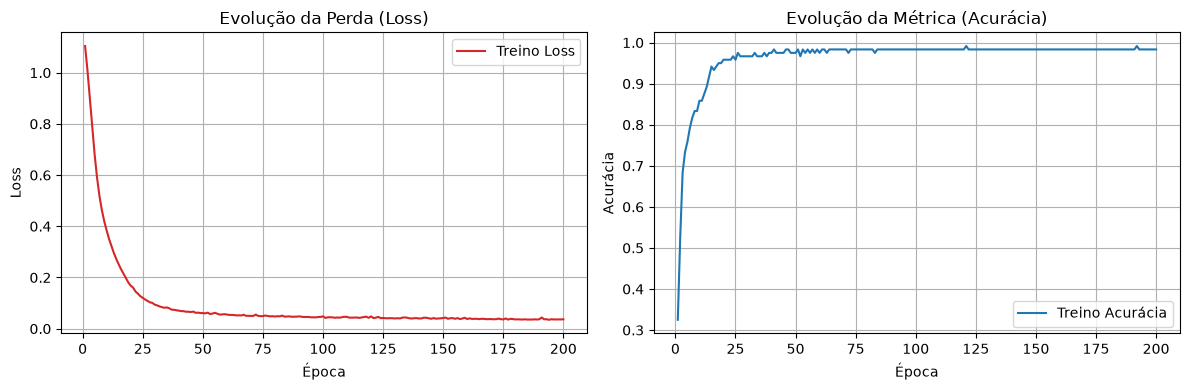

Teste Fold 1 ----- Acurácia: 1.0000 | F1-Score: 1.0000

--- Fold 2/5 ---
Gráficos de treinamento do Fold 2:


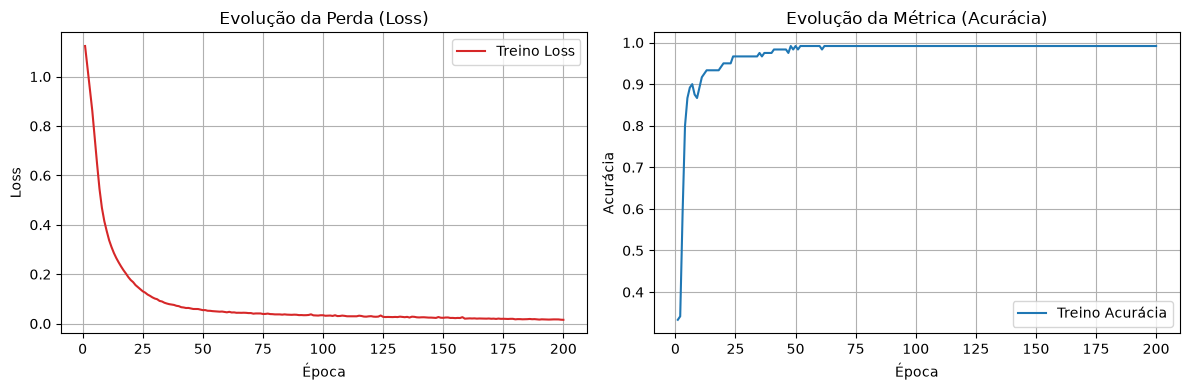

Teste Fold 2 ----- Acurácia: 0.9667 | F1-Score: 0.9585

--- Fold 3/5 ---
Gráficos de treinamento do Fold 3:


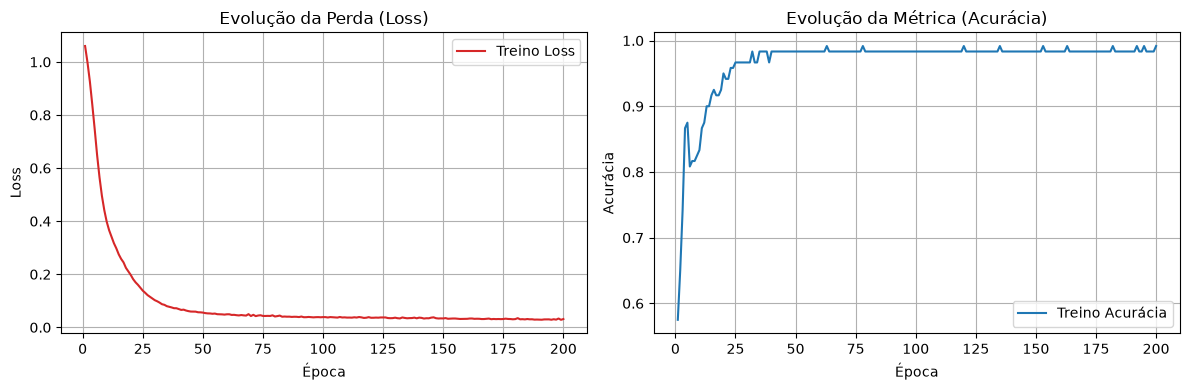

Teste Fold 3 ----- Acurácia: 0.9667 | F1-Score: 0.9628

--- Fold 4/5 ---
Gráficos de treinamento do Fold 4:


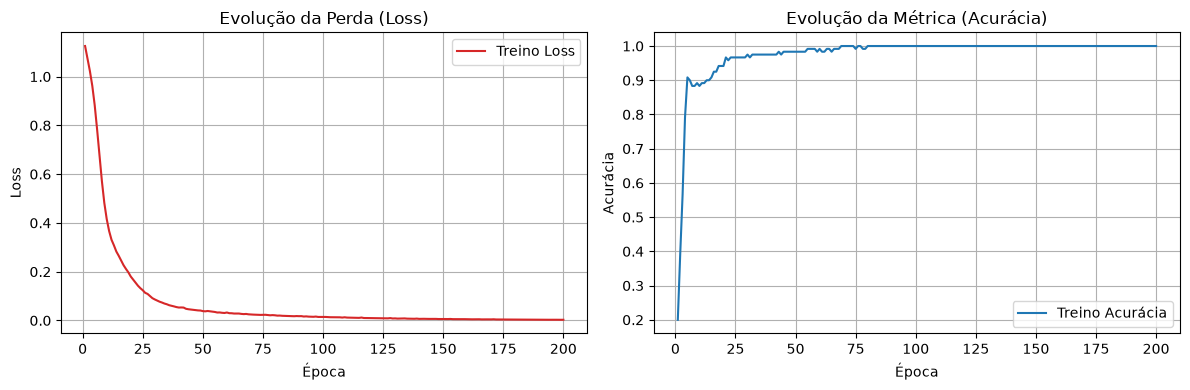

Teste Fold 4 ----- Acurácia: 0.9333 | F1-Score: 0.9373

--- Fold 5/5 ---
Gráficos de treinamento do Fold 5:


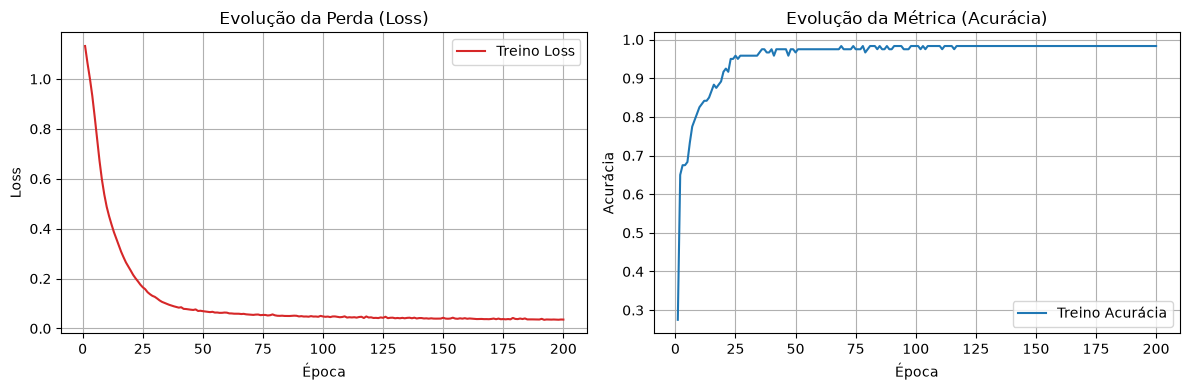

Teste Fold 5 ----- Acurácia: 0.9667 | F1-Score: 0.9710

------------------------------------------
Resultado Final ----- Acurácia Média: 0.9667



In [5]:
dataset_iris = load_iris()
X_iris = dataset_iris.data
y_iris = dataset_iris.target

train_and_eval_kfold(
    features=X_iris,
    targets=y_iris,
    input_dim=4,
    output_dim=3,
    hidden_dim1=32,
    hidden_dim2=16,
    task_type='classification',
    k_folds=5,
    batch=8,
    epochs=200,
    lr=0.001
)

=== INICIANDO TREINAMENTO: Tarefa de CLASSIFICATION ===

--- Fold 1/5 ---
Gráficos de treinamento do Fold 1:


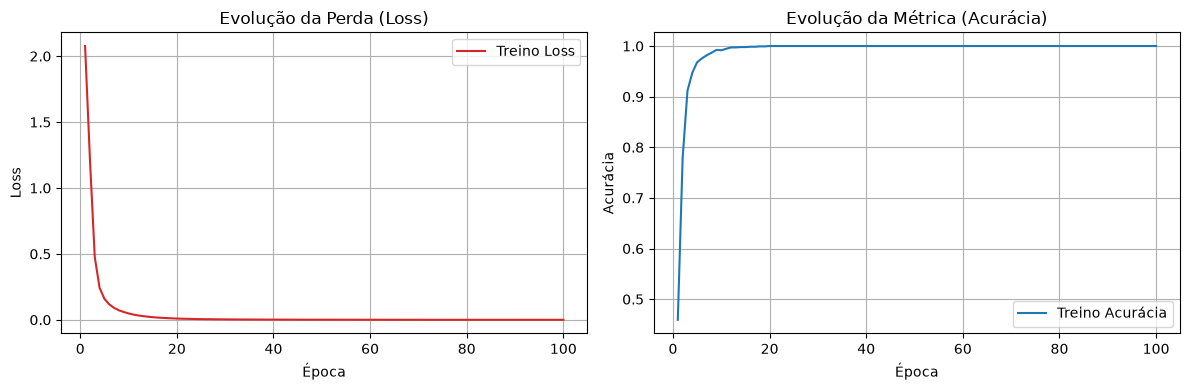

Teste Fold 1 ----- Acurácia: 0.9722 | F1-Score: 0.9732

--- Fold 2/5 ---
Gráficos de treinamento do Fold 2:


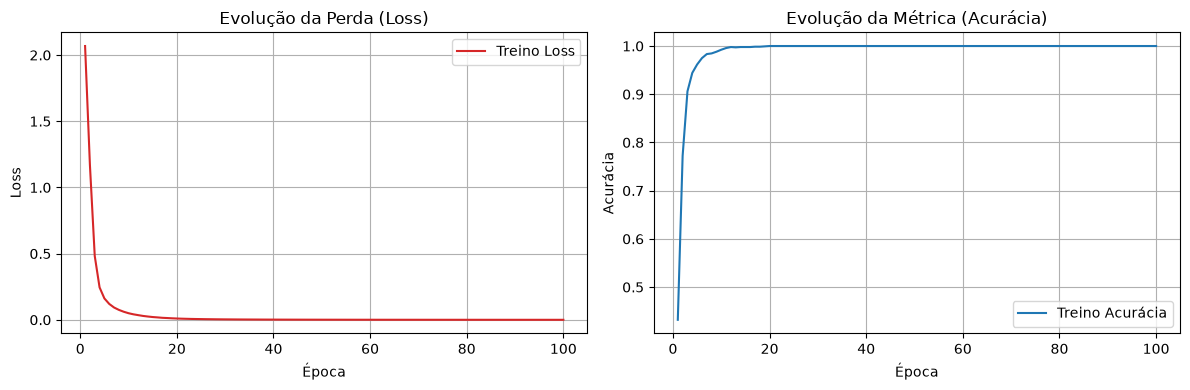

Teste Fold 2 ----- Acurácia: 0.9694 | F1-Score: 0.9697

--- Fold 3/5 ---
Gráficos de treinamento do Fold 3:


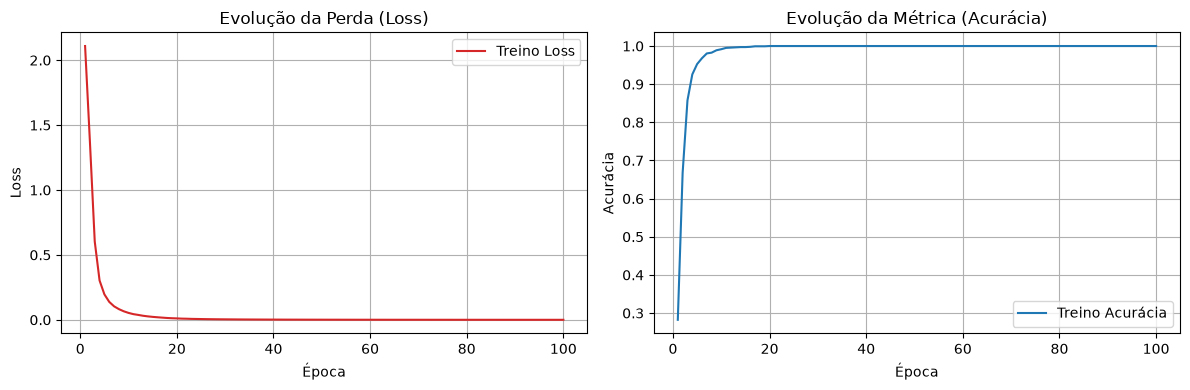

Teste Fold 3 ----- Acurácia: 0.9777 | F1-Score: 0.9767

--- Fold 4/5 ---
Gráficos de treinamento do Fold 4:


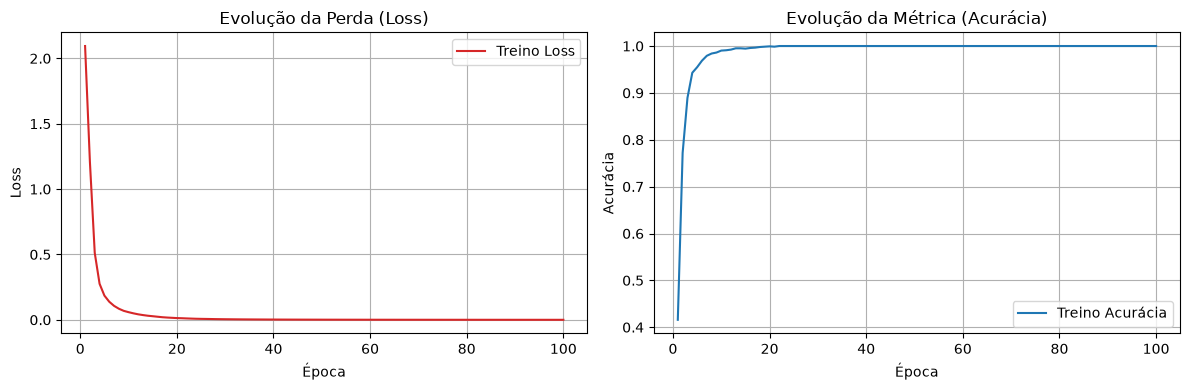

Teste Fold 4 ----- Acurácia: 0.9889 | F1-Score: 0.9883

--- Fold 5/5 ---
Gráficos de treinamento do Fold 5:


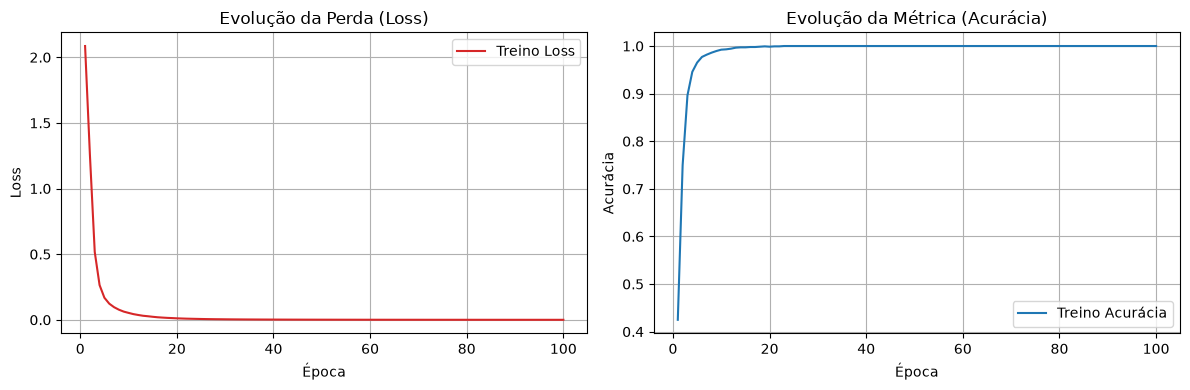

Teste Fold 5 ----- Acurácia: 0.9666 | F1-Score: 0.9679

------------------------------------------
Resultado Final ----- Acurácia Média: 0.9750



In [6]:
dataset_digits = load_digits()
X_digits = dataset_digits.data
y_digits = dataset_digits.target

train_and_eval_kfold(
    features=X_digits,
    targets=y_digits,
    input_dim=64,
    output_dim=10,
    hidden_dim1=64,
    hidden_dim2=32,
    task_type='classification',
    k_folds=5,
    batch=32,
    epochs=100,
    lr=0.001
)

=== INICIANDO TREINAMENTO: Tarefa de REGRESSION ===

--- Fold 1/5 ---
Gráficos de treinamento do Fold 1:


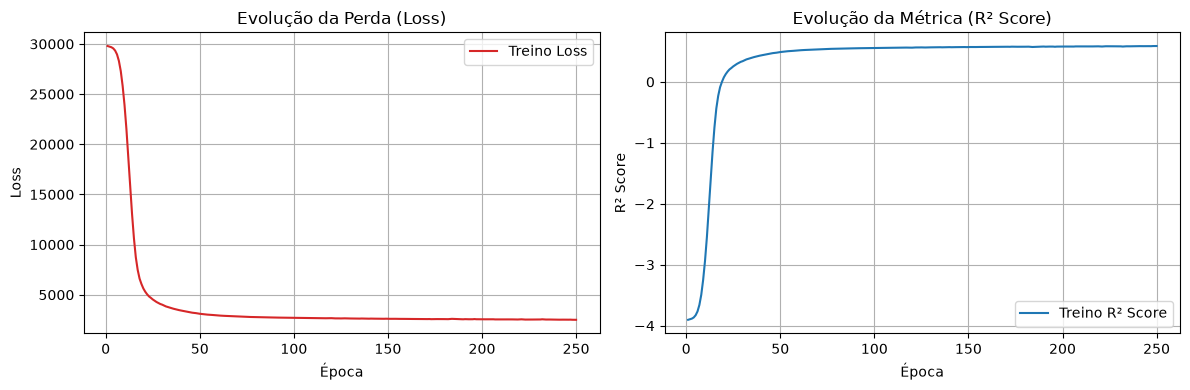

Teste Fold 1 ----- R² Score: 0.4908 | RMSE: 51.9420

--- Fold 2/5 ---
Gráficos de treinamento do Fold 2:


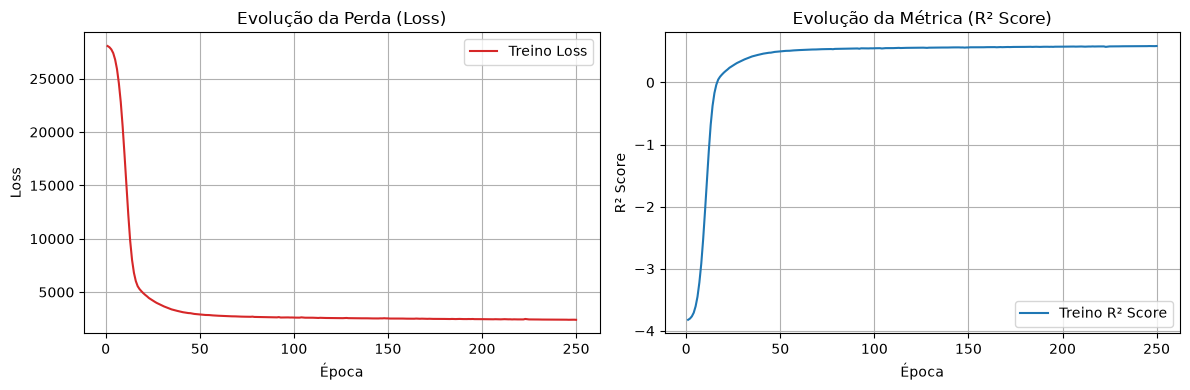

Teste Fold 2 ----- R² Score: 0.5448 | RMSE: 53.2878

--- Fold 3/5 ---
Gráficos de treinamento do Fold 3:


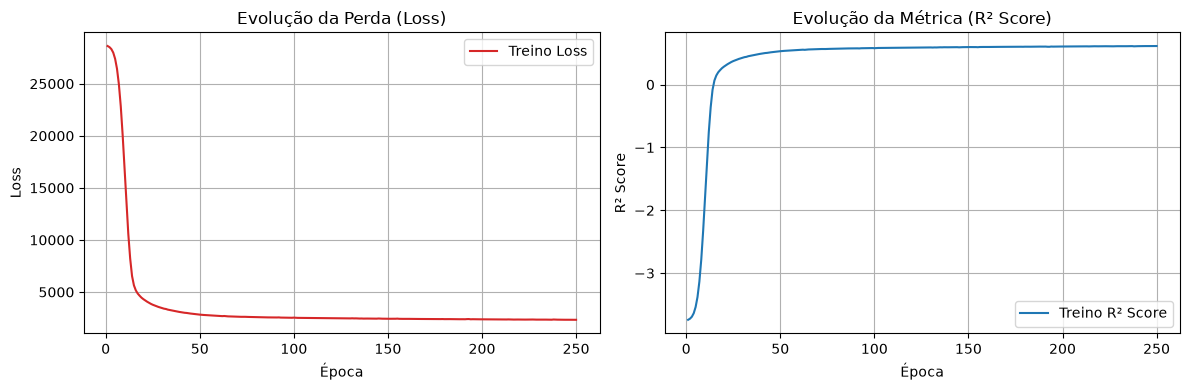

Teste Fold 3 ----- R² Score: 0.3538 | RMSE: 59.3083

--- Fold 4/5 ---
Gráficos de treinamento do Fold 4:


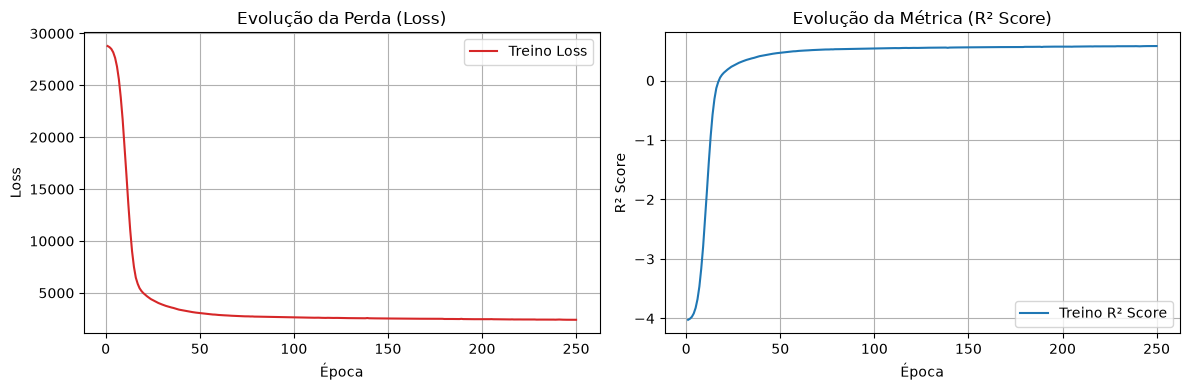

Teste Fold 4 ----- R² Score: 0.5419 | RMSE: 55.5235

--- Fold 5/5 ---
Gráficos de treinamento do Fold 5:


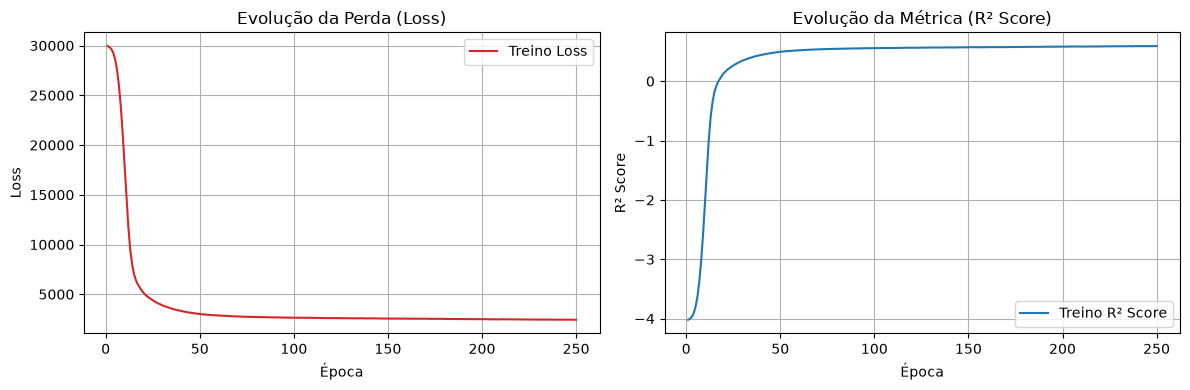

Teste Fold 5 ----- R² Score: 0.4655 | RMSE: 54.6480

------------------------------------------
Resultado Final ----- R² Médio: 0.4794



In [7]:
dataset_diabetes = load_diabetes()
X_diabetes = dataset_diabetes.data
y_diabetes = np.expand_dims(dataset_diabetes.target, axis=1)

train_and_eval_kfold(
    features=X_diabetes,
    targets=y_diabetes,
    input_dim=10,
    output_dim=1,
    hidden_dim1=32,
    hidden_dim2=16,
    task_type='regression',
    k_folds=5,
    batch=16,
    epochs=250,
    lr=0.001
)